# Initial setup
The below code has to be run only once to download all necessary files and convert them to the necessary formats used in later sections of this document.

In [1]:
import torch

#device = "cuda" if torch.cuda.is_available() else "cpu"
device = "cpu"

In [ ]:
# downloading the model
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224",
    local_dir="./model/biomedclip",
)

In [ ]:
# downloading the BoghdadyJR/radiology dataset
from datasets import load_dataset

ds = load_dataset("BoghdadyJR/radiology", split="train")
ds.save_to_disk("./datasets/radiology/train")
ds = load_dataset("BoghdadyJR/radiology", split="test")
ds.save_to_disk("./datasets/radiology/test")

In [ ]:
# automatically download ROCOv2 dataset from Zenodo and save to disk
from pathlib import Path
from urllib.request import urlretrieve

def download(path: str, url: str):
    output_path = Path(path)
    if output_path.exists():
        print(f"{output_path} already exists, skipping download.")
        return
    output_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(url, output_path)

download("./datasets/ROCOv2/cui_mapping.csv", "https://zenodo.org/records/10821435/files/cui_mapping.csv?download=1")
download("./datasets/ROCOv2/license_information.csv", "https://zenodo.org/records/10821435/files/license_information.csv?download=1")
download("./datasets/ROCOv2/test_captions.csv", "https://zenodo.org/records/10821435/files/test_captions.csv?download=1")
download("./datasets/ROCOv2/test_concepts.csv", "https://zenodo.org/records/10821435/files/test_concepts.csv?download=1")
download("./datasets/ROCOv2/test_concepts_manual.csv", "https://zenodo.org/records/10821435/files/test_concepts_manual.csv?download=1")
download("./datasets/ROCOv2/test_images.zip", "https://zenodo.org/records/10821435/files/test_images.zip?download=1")
download("./datasets/ROCOv2/train_captions.csv", "https://zenodo.org/records/10821435/files/train_captions.csv?download=1")
download("./datasets/ROCOv2/train_concepts.csv", "https://zenodo.org/records/10821435/files/train_concepts.csv?download=1")
download("./datasets/ROCOv2/train_concepts_manual.csv", "https://zenodo.org/records/10821435/files/train_concepts_manual.csv?download=1")
download("./datasets/ROCOv2/train_images.zip", "https://zenodo.org/records/10821435/files/train_images.zip?download=1")
download("./datasets/ROCOv2/valid_captions.csv", "https://zenodo.org/records/10821435/files/valid_captions.csv?download=1")
download("./datasets/ROCOv2/valid_concepts.csv", "https://zenodo.org/records/10821435/files/valid_concepts.csv?download=1")
download("./datasets/ROCOv2/valid_concepts_manual.csv", "https://zenodo.org/records/10821435/files/valid_concepts_manual.csv?download=1")
download("./datasets/ROCOv2/valid_images.zip", "https://zenodo.org/records/10821435/files/valid_images.zip?download=1")

In [ ]:
# loading ROCOv2 dataset from raw files first
import csv
import os
import zipfile
from datasets import Dataset, Features, Sequence, Value, Image as HFImage
from tqdm import tqdm
from pathlib import Path
import pickle as pkl

def convert_concepts(concept_string: str, cui_to_idx: dict[str, int]) -> list[int]:
    if not concept_string:
        return []
    return [cui_to_idx[cui] for cui in concept_string.split(";") if cui and cui in cui_to_idx]

def load_roco_dataset(
    path: str,
    split: str
) -> tuple[Dataset, list[str]]:
    # check if all files exist
    required_files = [
        f"{split}_captions.csv",
        f"{split}_concepts_manual.csv",
        f"{split}_concepts.csv",
        f"{split}_images.zip",
        "cui_mapping.csv",
    ]
    for filename in required_files:
        filepath = os.path.join(path, filename)
        if not os.path.isfile(filepath):
            raise FileNotFoundError(
                f"Required file not found: {filepath}. "
                f"The split may be unknown or incomplete."
            )
    # load cui mapping
    cui_to_idx = {}
    concept_mapping = []

    with open(os.path.join(path, "cui_mapping.csv"), "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        _ = next(reader) # header line
        for row in reader:
            cui = row[0]
            concept_name = row[1]
            idx = len(concept_mapping)
            cui_to_idx[cui] = idx
            concept_mapping.append(concept_name)

    with open(os.path.join(path, f"{split}_captions.csv"), "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        _ = next(reader) # header line
        caption_dict = {
            row[0]: row[1]
            for row in list(reader)
        }

    with open(os.path.join(path, f"{split}_concepts.csv"), "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        _ = next(reader) # header line
        concepts_dict = {
            row[0]: row[1]
            for row in list(reader)
        }

    with open(os.path.join(path, f"{split}_concepts_manual.csv"), "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        _ = next(reader) # header line
        concepts_manual_dict = {
            row[0]: row[1]
            for row in list(reader)
        }
    
    features = Features({
        "id": Value("string"),
        "image": HFImage(),
        "concepts": Sequence(Value("int64")),
        "concepts_manual": Sequence(Value("int64")),
        "caption": Value("string"),
    })

    def generate_samples():
        with zipfile.ZipFile(os.path.join(path, f"{split}_images.zip"), "r") as archive:
            image_files = {
                Path(name).name: name
                for name in archive.namelist()
                if name.lower().endswith(".jpg")
            }

            for image_id, caption in tqdm(caption_dict.items(), desc="Processing images"):
                if image_id not in concepts_dict:
                    raise ValueError(f"Missing concepts entry for ID {image_id}")
                if image_id not in concepts_manual_dict:
                    raise ValueError(f"Missing manual concepts entry for ID {image_id}")
                image_filename = f"{image_id}.jpg"
                if image_filename not in image_files:
                    raise FileNotFoundError(f"Image {image_filename} not found in archive.")
                image_bytes = archive.read(image_files[image_filename])
                yield {
                    "id": image_id,
                    "image": {
                        "bytes": image_bytes,
                        "path": None,
                    },
                    "concepts": convert_concepts(concepts_dict[image_id], cui_to_idx),
                    "concepts_manual": convert_concepts(concepts_manual_dict[image_id], cui_to_idx),
                    "caption": caption,
                }
    dataset = Dataset.from_generator(
        generate_samples,
        features=features,
        writer_batch_size=16,
        keep_in_memory=False,
    )
    return dataset, concept_mapping

ds, cui = load_roco_dataset("./datasets/ROCOv2", "test")
ds.save_to_disk("./datasets/roco/test")
with open("./datasets/roco/test/cui.pkl", "wb") as f:
    pkl.dump(cui, f)
ds, cui = load_roco_dataset("./datasets/ROCOv2", "train")
ds.save_to_disk("./datasets/roco/train")
with open("./datasets/roco/train/cui.pkl", "wb") as f:
    pkl.dump(cui, f)
    ds, cui = load_roco_dataset("./datasets/ROCOv2", "valid")
ds.save_to_disk("./datasets/roco/valid")
with open("./datasets/roco/valid/cui.pkl", "wb") as f:
    pkl.dump(cui, f)

In [2]:
# reloading the dataset BoghdadyJR/radiology from local backup (now includes caching index)
from datasets import load_from_disk
ds_rad = load_from_disk("./datasets/radiology/test")

In [3]:
# reloading the dataset ROCOv2 from local backup (now includes caching index)
from datasets import load_from_disk
import pickle as pkl
ds_roco = load_from_disk("./datasets/roco/test")
with open("./datasets/roco/test/cui.pkl", "rb") as f:
    ds_roco_cui: list[str] = pkl.load(f)

In [7]:
# loading the model from local backup
from open_clip import create_model_and_transforms, get_tokenizer
from open_clip.factory import HF_HUB_PREFIX, _MODEL_CONFIGS
from open_clip.tokenizer import HFTokenizer
from open_clip.model import CLIP
import json
from torchvision.transforms.transforms import Compose
from typing import cast, Callable
from PIL.Image import Image

model_name = "biomedclip_local"
with open("model/biomedclip/open_clip_config.json", "r") as f:
    config = json.load(f)
    model_cfg = config["model_cfg"]
    preprocess_cfg = config["preprocess_cfg"]


if (not model_name.startswith(HF_HUB_PREFIX)
    and model_name not in _MODEL_CONFIGS
    and config is not None):
    _MODEL_CONFIGS[model_name] = model_cfg

tokenizer: HFTokenizer = cast(
    HFTokenizer,
    get_tokenizer("local-dir:model/biomedclip"),
)

model, _, preprocess = cast(
    tuple[CLIP, None, Callable[[Image], torch.Tensor]],
    create_model_and_transforms(
    model_name=model_name,
    pretrained="model/biomedclip/open_clip_pytorch_model.bin",
    **{f"image_{k}": v for k, v in preprocess_cfg.items()},
))
model.to(device)

if not isinstance(preprocess, Compose):
    raise ValueError(f"Expected Compose, got {type(preprocess)}")
if not isinstance(tokenizer, HFTokenizer):
    raise ValueError(f"Expected HFTokenizer, got {type(tokenizer)}")

model.eval()
None

In [ ]:
# run embeddings for all the data and save them to disk
from PIL.Image import Image
import pickle as pkl
from tqdm import tqdm
context_length = 256
batch_size = 100
dataset = ds_roco
image_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
caption_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
concept_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
caption_concept_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
logit_scales = torch.zeros((len(dataset), 1), dtype=torch.float32)

for start in tqdm(range(0, len(dataset), batch_size)):
    end = min(start + batch_size, len(dataset))
    images = cast(list[Image], dataset[start:end]['image'])
    captions = cast(list[str], dataset[start:end]["caption"])
    concepts = cast(list[str], [" ".join([ds_roco_cui[c] for c in cs]) for cs in dataset[start:end]["concepts"]])
    caption_concepts = [f"{c} {cap}" for c, cap in zip(concepts, captions)]
    images_processed = torch.stack([preprocess(img) for img in images]).to(device)
    texts = tokenizer(captions + concepts + caption_concepts, context_length=context_length).to(device)
    with torch.no_grad():
        image_features, text_features, logit_scale = model(images_processed, texts)
        image_embeddings[start:end] = image_features[:len(images)]
        caption_embeddings[start:end] = text_features[:len(captions)]
        concept_embeddings[start:end] = text_features[len(captions):len(captions)+len(concepts)]
        caption_concept_embeddings[start:end] = text_features[len(captions)+len(concepts):]
        logit_scales[start:end] = logit_scale

with open("./datasets/roco/test/image_embeddings.pkl", "wb") as f:
    pkl.dump(image_embeddings.cpu().detach(), f)
with open("./datasets/roco/test/caption_embeddings.pkl", "wb") as f:
    pkl.dump(caption_embeddings.cpu().detach(), f)
with open("./datasets/roco/test/concept_embeddings.pkl", "wb") as f:
    pkl.dump(concept_embeddings.cpu().detach(), f)
with open("./datasets/roco/test/caption_concept_embeddings.pkl", "wb") as f:
    pkl.dump(caption_concept_embeddings.cpu().detach(), f)
with open("./datasets/roco/test/logit_scales.pkl", "wb") as f:
    pkl.dump(logit_scales.cpu().detach(), f)

context_length = 256
batch_size = 100
dataset = ds_rad
image_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
caption_embeddings = torch.zeros((len(dataset), 512), dtype=torch.float32)
logit_scales = torch.zeros((len(dataset), 1), dtype=torch.float32)

for start in tqdm(range(0, len(dataset), batch_size)):
    end = min(start + batch_size, len(dataset))
    images = cast(list[Image], dataset[start:end]['image'])
    captions = cast(list[str], dataset[start:end]["caption"])
    images_processed = torch.stack([preprocess(img) for img in images]).to(device)
    texts = tokenizer(captions, context_length=context_length).to(device)
    with torch.no_grad():
        image_features, text_features, logit_scale = model(images_processed, texts)
        image_embeddings[start:end] = image_features[:len(images)]
        caption_embeddings[start:end] = text_features[:len(captions)]
        logit_scales[start:end] = logit_scale

with open("./datasets/radiology/test/image_embeddings.pkl", "wb") as f:
    pkl.dump(image_embeddings.cpu().detach(), f)
with open("./datasets/radiology/test/caption_embeddings.pkl", "wb") as f:
    pkl.dump(caption_embeddings.cpu().detach(), f)
with open("./datasets/radiology/test/logit_scales.pkl", "wb") as f:
    pkl.dump(logit_scales.cpu().detach(), f)

In [10]:
import torch
import pickle as pkl
from tqdm import tqdm
context_length = 256
batch_size = 100

cui_embeddings = torch.zeros((len(ds_roco_cui), 512), dtype=torch.float32)
images_processed = torch.zeros((0, 3, 224, 224)).to(device)
for start in tqdm(range(0, len(ds_roco_cui), batch_size)):
    end = min(start + batch_size, len(ds_roco_cui))
    texts = tokenizer(ds_roco_cui[start:end], context_length=context_length).to(device)
    with torch.no_grad():
        _, text_features, _ = model(images_processed, texts)
        cui_embeddings[start:end] = text_features.cpu().detach()
with open("./datasets/roco/test/cui_embeddings.pkl", "wb") as f:
    pkl.dump(cui_embeddings.cpu().detach(), f)

100%|██████████| 20/20 [05:38<00:00, 16.93s/it]


<hr>

# Exploration

In [1]:
import torch

#device = "cuda" if torch.cuda.is_available() else "cpu"
device = "cpu"

In [2]:
# loading the model from local backup
from open_clip import create_model_and_transforms, get_tokenizer
from open_clip.factory import HF_HUB_PREFIX, _MODEL_CONFIGS
from open_clip.tokenizer import HFTokenizer
from open_clip.model import CLIP
import json
from torchvision.transforms.transforms import Compose
from typing import cast, Callable
from PIL.Image import Image

model_name = "biomedclip_local"
with open("model/biomedclip/open_clip_config.json", "r") as f:
    config = json.load(f)
    model_cfg = config["model_cfg"]
    preprocess_cfg = config["preprocess_cfg"]


if (not model_name.startswith(HF_HUB_PREFIX)
    and model_name not in _MODEL_CONFIGS
    and config is not None):
    _MODEL_CONFIGS[model_name] = model_cfg

tokenizer: HFTokenizer = cast(
    HFTokenizer,
    get_tokenizer("local-dir:model/biomedclip"),
)

model, _, preprocess = cast(
    tuple[CLIP, None, Callable[[Image], torch.Tensor]],
    create_model_and_transforms(
    model_name=model_name,
    pretrained="model/biomedclip/open_clip_pytorch_model.bin",
    **{f"image_{k}": v for k, v in preprocess_cfg.items()},
))
model.to(device)

if not isinstance(preprocess, Compose):
    raise ValueError(f"Expected Compose, got {type(preprocess)}")
if not isinstance(tokenizer, HFTokenizer):
    raise ValueError(f"Expected HFTokenizer, got {type(tokenizer)}")

model.eval()
None

In [2]:
# loading the dataset BoghdadyJR/radiology from local backup
from datasets import load_from_disk
ds_rad = load_from_disk("./datasets/radiology/test")

In [12]:
ds_rad[0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=600x346>,
 'image_id': 'ROCO_00020',
 'caption': ' Axial computed tomography scan of the pelvis showing a diffuse infiltration of the bladder wall, catheter in situ (arrow).\n',
 'modality': 'ct'}

In [3]:
# loading the dataset ROCOv2 from local backup
from datasets import load_from_disk
import pickle as pkl
ds_roco = load_from_disk("./datasets/roco/test")
with open("./datasets/roco/test/cui.pkl", "rb") as f:
    ds_roco_cui: list[str] = pkl.load(f)

In [17]:
ds_roco[0]

{'id': 'ROCOv2_2023_test_000001',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=653x658>,
 'concepts': [776, 368],
 'concepts_manual': [776],
 'caption': 'CT chest axial view showing a huge ascending aortic aneurysm (*).'}

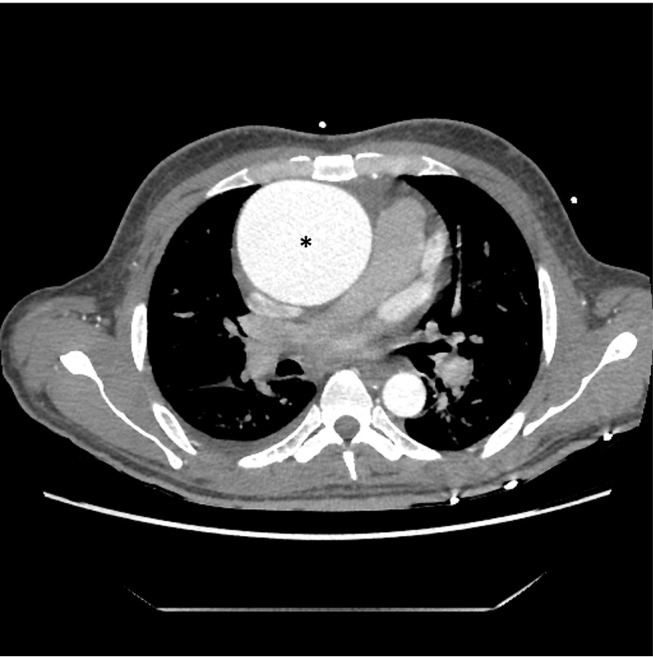

In [18]:
ds_roco[0]['image']

In [4]:
import pickle as pkl
with open("./datasets/roco/test/image_embeddings.pkl", "rb") as f:
    roco_image_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/caption_embeddings.pkl", "rb") as f:
    roco_caption_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/concept_embeddings.pkl", "rb") as f:
    roco_concept_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/caption_concept_embeddings.pkl", "rb") as f:
    roco_caption_concept_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/roco/test/cui_embeddings.pkl", "rb") as f:
    roco_cui_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/radiology/test/image_embeddings.pkl", "rb") as f:
    rad_image_embeddings: torch.Tensor = pkl.load(f)
with open("./datasets/radiology/test/caption_embeddings.pkl", "rb") as f:
    rad_caption_embeddings: torch.Tensor = pkl.load(f)
logit_scale = 85.2322769165039 # taken from model output, seems to be fixed for any model input

Image:


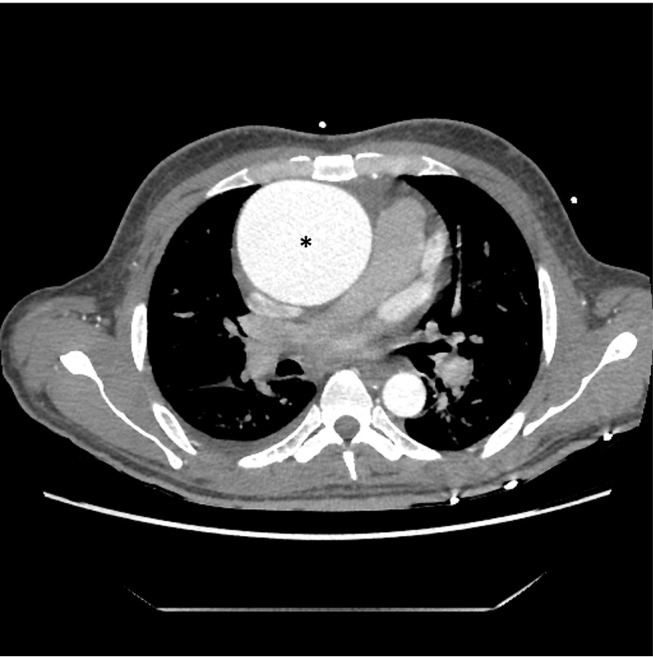

Real label: CT chest axial view showing a huge ascending aortic aneurysm (*).
Top predicted labels:
CT chest axial view showing a huge ascending aortic aneurysm (*).: 0.9999934434890747
Chest CT at relapse showed pericardial effusion and ground glass bilateral opacities.: 3.1820145522942767e-06
Postoperative computed tomography angiography showing that the left internal mammary artery graft was patent, with good distal run-off in the left anterior descending artery.: 2.149521606042981e-06
Thoracic computed tomography scan revealing obstruction of the right lower bronchus by a contrast-enhanced intraluminal lesion of 2.5 cm in diameter.: 8.566938731746632e-07
Computed tomography (CT) shows floating thrombosis (white arrow): 1.8061015794046398e-07


In [19]:
# toy classification example (predicting which of the first 100 captions is the correct one for the first image in the ROCOv2 test dataset)
# based on official example from https://huggingface.co/microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224

import torch
from PIL.Image import Image
context_length = 256

template = "This is a radiology image of "
images = cast(list[Image], ds_roco[:1]['image'])
labels = cast(list[str], ds_roco[:100]["caption"])
images_processed = torch.stack([preprocess(img) for img in images]).to(device)
texts = tokenizer([template + l for l in labels], context_length=context_length).to(device)
with torch.no_grad():
    image_features, text_features, logit_scale = model(images_processed, texts)

    logits = (logit_scale * image_features @ text_features.t()).detach().softmax(dim=-1)
    sorted_indices = torch.argsort(logits, dim=-1, descending=True)

    logits = logits.cpu().numpy()
    sorted_indices = sorted_indices.cpu().numpy()

print(f"Image:")
display(images[0])
print(f"Real label: {labels[0]}")
print(f"Top predicted labels:")
top_k = 5
for j in range(top_k):
    jth_index = sorted_indices[0][j]
    print(f'{labels[jth_index]}: {logits[0][jth_index]}')

Label: CT chest axial view showing a huge ascending aortic aneurysm (*).
Real image:


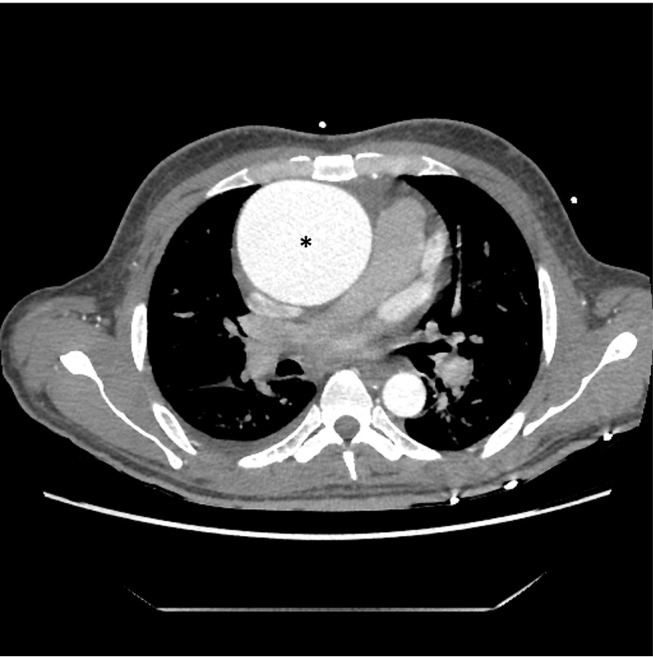

Predicted image:


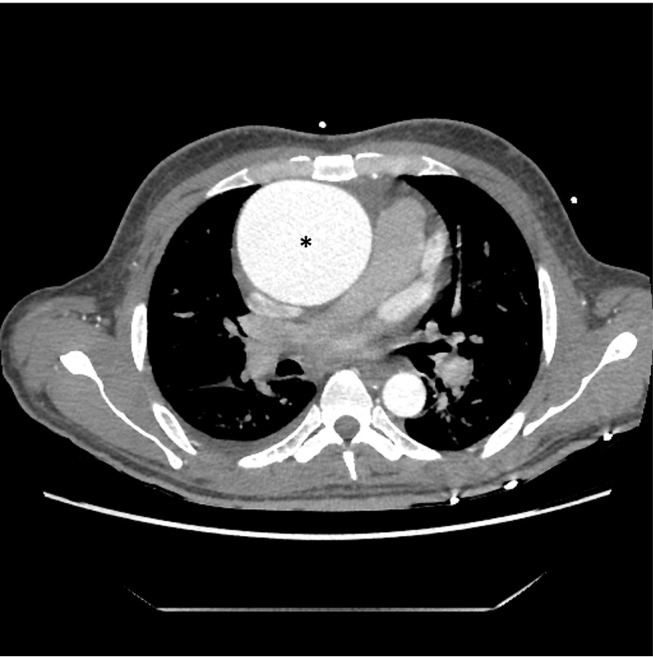

In [20]:
# toy image retrieval example (predicting which of the first 100 images fits the first caption in the ROCOv2 test dataset best)

import torch
from PIL.Image import Image
context_length = 256

template = "This is a radiology image of "
images = cast(list[Image], ds_roco[:100]['image'])
labels = cast(list[str], ds_roco[:1]["caption"])
images_processed = torch.stack([preprocess(img) for img in images]).to(device)
texts = tokenizer([template + l for l in labels], context_length=context_length).to(device)
with torch.no_grad():
    image_features, text_features, logit_scale = model(images_processed, texts)

    logits = (logit_scale * image_features @ text_features.t()).t().detach().softmax(dim=-1)
    sorted_indices = torch.argsort(logits, dim=-1, descending=True)

    logits = logits.cpu().numpy()
    sorted_indices = sorted_indices.cpu().numpy()

print(f"Label: {labels[0]}")
print(f"Real image:")
display(images[0])
print(f"Predicted image:")
display(images[sorted_indices[0][0]])

In [21]:
import torch
from PIL.Image import Image

context_length = 256

images = cast(list[Image], ds_roco[:100]['image'])
labels = cast(list[str], ds_roco[:100]["caption"])
images_processed = torch.stack([preprocess(img) for img in images]).to(device)
texts = tokenizer(labels, context_length=context_length).to(device)
with torch.no_grad():
    image_features, text_features, logit_scale = model(images_processed, texts)

    logits = (logit_scale * image_features @ text_features.t()).detach()
    pred_labels = logits.softmax(dim=-1).argmax(dim=-1)
    pred_images = logits.t().softmax(dim=-1).argmax(dim=-1)
correct_labels = torch.count_nonzero(pred_labels == torch.arange(len(labels)).to(device))
correct_images = torch.count_nonzero(pred_images == torch.arange(len(images)).to(device))
correct_labels, correct_images

(tensor(83), tensor(87))

In [8]:
def show_image_and_caption(index: int):
    display(ds_roco[index]['image'])
    print(ds_roco[index]['caption'])

In [35]:
pred_labels, pred_images

(tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
          3, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
         36, 37, 38, 39, 61, 95, 42, 43, 71, 45, 68, 99, 46, 46, 50, 70, 83, 53,
         54, 55, 56, 56, 58, 34, 60, 95, 62, 63, 64, 65, 66, 66, 68, 69, 70, 71,
         72, 73, 74, 75, 76, 77, 14, 79, 80, 81, 82, 83, 84, 85, 64, 87, 88, 89,
         90, 91, 92, 93, 37, 95, 96, 97, 98, 99]),
 tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
         18, 19, 98, 21, 22, 23, 24, 25, 26, 27, 28, 44, 30, 31, 32, 33, 34, 35,
         36, 37, 38, 39, 53, 41, 42, 43, 44, 45, 48, 68, 50, 48, 50, 51, 52, 53,
         54, 55, 57, 57, 58, 34, 60, 61, 62, 63, 64, 65, 66, 29, 68, 69, 70, 44,
         72, 73, 74, 75, 76, 77, 16, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89,
         90, 91, 92, 93, 94, 61, 96, 97, 98, 99]))

In [34]:
wrongly_predicted_labels = torch.arange(len(labels)).to(device)[pred_labels != torch.arange(len(labels)).to(device)]
wrongly_predicted_images = torch.arange(len(images)).to(device)[pred_images != torch.arange(len(images)).to(device)]
wrongly_predicted_labels, wrongly_predicted_images

(tensor([18, 40, 41, 44, 46, 47, 48, 49, 51, 52, 57, 59, 61, 67, 78, 86, 94]),
 tensor([20, 29, 40, 46, 47, 48, 49, 56, 59, 67, 71, 78, 95]))

In [ ]:
_ = show_image_and_caption(18), show_image_and_caption(3)

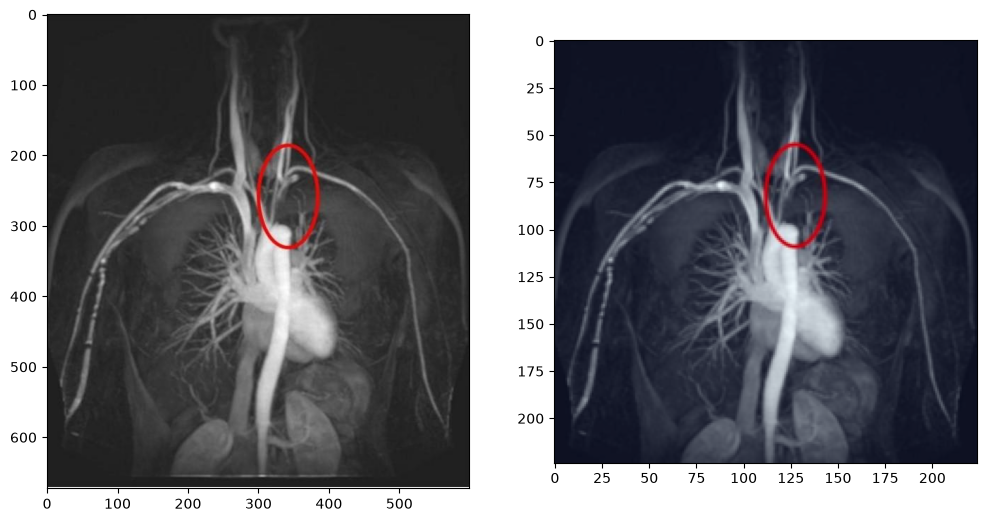

In [40]:
# what does the prepocessor do?
from matplotlib import pyplot as plt

img: Image = cast(Image, ds_rad[2]['image'])
img_torch = preprocess(img)
# display tensor of shape (3, 224, 224) as RGB image
fig, axs = plt.subplots(1, 2, figsize=(12, 7))
axs[0].imshow(img)
axs[1].imshow((img_torch.permute(1, 2, 0) - img_torch.min().item()) / (img_torch.max().item() - img_torch.min().item()))
None
# -> not much, just clipping, resizing and some normalization

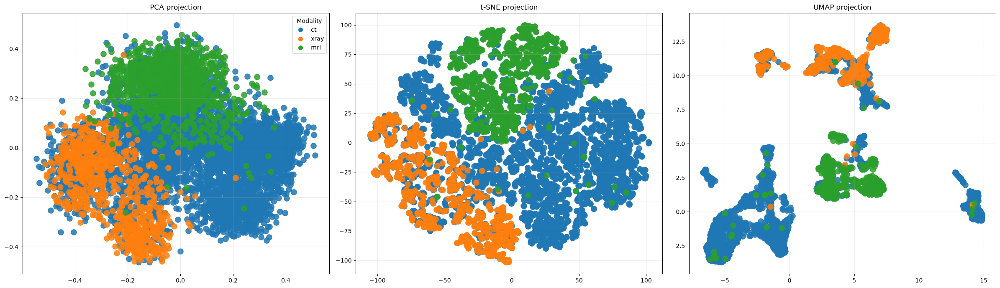

In [ ]:
# images plotted in embedding space projected into 2d
# colored by image modality
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
samples = len(ds_rad)

embeddings = rad_image_embeddings[:samples].cpu().numpy()
modalities = ds_rad[:samples]["modality"]

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

unique_modalities = list(dict.fromkeys(modalities))
colors = plt.cm.tab10(range(len(unique_modalities)))
color_map = dict(zip(unique_modalities, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for modality in unique_modalities:
        mask = [m == modality for m in modalities]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[modality]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

modality_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=modality,
        markerfacecolor=color_map[modality],
        markersize=9,
    )
    for modality in unique_modalities
]

axes[0].legend(handles=modality_handles, title="Modality", loc="best")

plt.tight_layout()
plt.show()

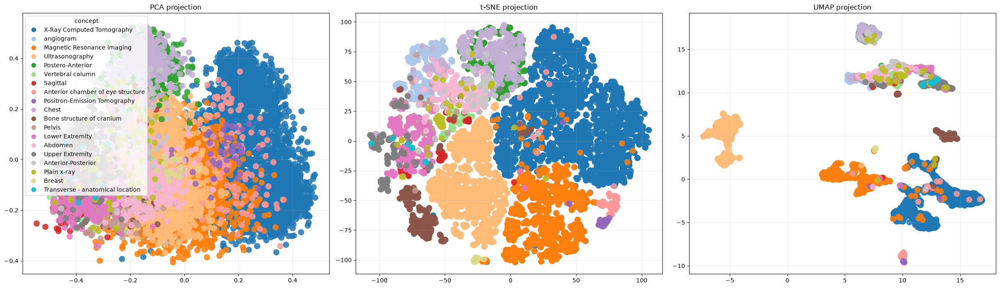

In [ ]:
# images plotted in embedding space projected into 2d
# colored by least common concept in each list
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from typing import cast
samples = len(ds_roco)

embeddings = roco_image_embeddings[:samples].cpu().numpy()
concepts = cast(list[list[int]], ds_roco[:samples]["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = [(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts] # least common concept in each list
#concepts = [(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts] # most common concept in each list

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

unique_concepts = list(dict.fromkeys(concepts))
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=ds_roco_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

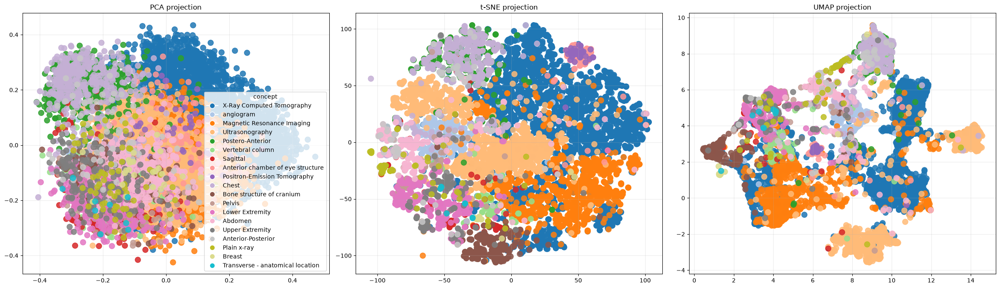

In [31]:
# captions plotted in embedding space projected into 2d
# colored by least common concept in each list
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from typing import cast
samples = len(ds_roco)

embeddings = roco_caption_embeddings[:samples].cpu().numpy()
concepts = cast(list[list[int]], ds_roco[:samples]["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = [(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts] # least common concept in each list
#concepts = [(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts] # most common concept in each list

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

unique_concepts = list(dict.fromkeys(concepts))
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=ds_roco_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

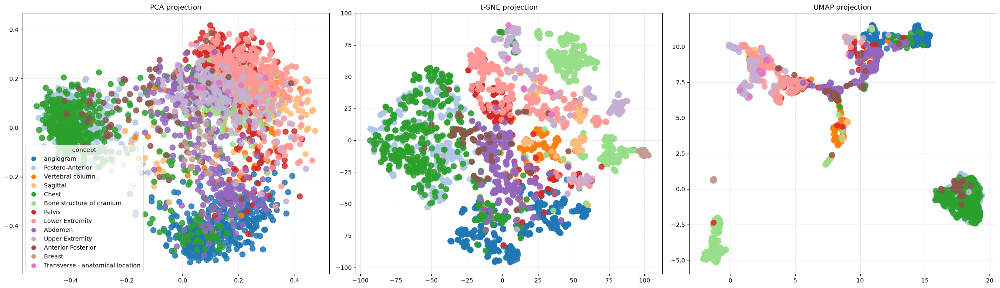

In [ ]:
# images plotted in embedding space projected into 2d
# colored by least common concept in each list, filtering out image modalities 
# (since these are large clusters that dominate the visualization, and are already shown in modality visualization above)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from typing import cast
samples = len(ds_roco)

embeddings = roco_image_embeddings.cpu().numpy()
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

unique_concepts = list(dict.fromkeys(concepts))
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=ds_roco_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

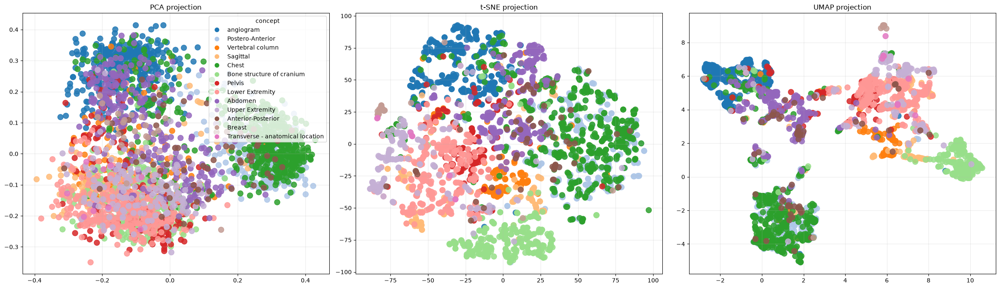

In [32]:
# captions plotted in embedding space projected into 2d
# colored by least common concept in each list, filtering out image modalities 
# (since these are large clusters that dominate the visualization, and are already shown in modality visualization above)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from typing import cast
samples = len(ds_roco)

embeddings = roco_caption_embeddings.cpu().numpy()
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

unique_concepts = list(dict.fromkeys(concepts))
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=ds_roco_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

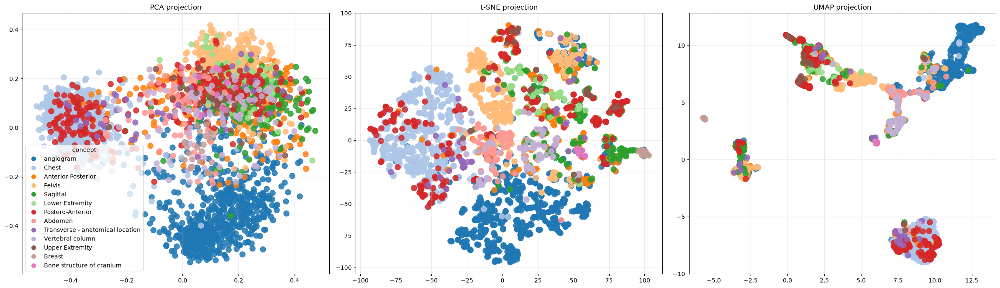

In [ ]:
# images plotted in embedding space projected into 2d
# colored by predicted most likely concept out of concepts from last figure
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from typing import cast
samples = len(ds_roco)

embeddings = roco_image_embeddings.cpu().numpy()
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]

# TODO: remove
# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]
unique_concepts = list(dict.fromkeys(concepts))

filtered_concept_embeddings = roco_cui_embeddings.cpu().numpy()[unique_concepts]
filtered_cui = [ds_roco_cui[c] for c in unique_concepts]
most_likely_concepts = np.argmax(embeddings @ filtered_concept_embeddings.T, axis=1)
unique_concepts = list(dict.fromkeys(most_likely_concepts))

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in most_likely_concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=filtered_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

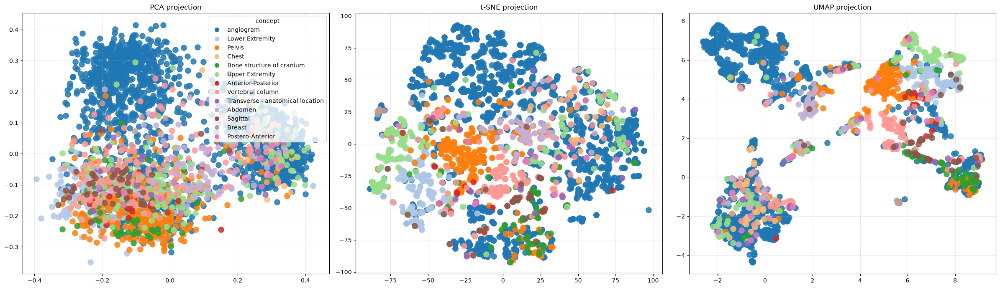

In [ ]:
# captions plotted in embedding space projected into 2d
# colored by predicted most likely concept out of concepts from last figure
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from typing import cast
samples = len(ds_roco)

embeddings = roco_caption_embeddings.cpu().numpy()
concepts = cast(list[list[int]], ds_roco["concepts_manual"])
#concepts = cast(list[str], ds_roco["concepts"])
filter_concepts = set([ds_roco_cui.index(c) for c in [
    'X-Ray Computed Tomography', 'Plain x-ray', 'Ultrasonography', 
    'Magnetic Resonance Imaging', 'PET/CT scan', 'Computed tomography imaging - action',
    'Positron-Emission Tomography'
]])
concepts = [[c for c in concept_list if c not in filter_concepts] for concept_list in concepts]

# filter concepts to least frequent ones
concept_counts = {}
for concept_list in concepts:
    for concept in concept_list:
        if concept not in concept_counts:
            concept_counts[concept] = 0
        concept_counts[concept] += 1
concepts = np.array([(sorted(concept_list, key=lambda c: (concept_counts[c], c))[0] if concept_list else -1) for concept_list in concepts]) # least common concept in each list
#concepts = np.array([(sorted(concept_list, key=lambda c: concept_counts[c])[-1] if concept_list else -1) for concept_list in concepts]) # most common concept in each list
embeddings = embeddings[concepts != -1][:samples]
concepts = concepts[concepts != -1][:samples]
unique_concepts = list(dict.fromkeys(concepts))

filtered_concept_embeddings = roco_cui_embeddings.cpu().numpy()[unique_concepts]
filtered_cui = [ds_roco_cui[c] for c in unique_concepts]
most_likely_concepts = np.argmax(embeddings @ filtered_concept_embeddings.T, axis=1)
unique_concepts = list(dict.fromkeys(most_likely_concepts))

pca_embeddings = PCA(n_components=2).fit_transform(embeddings)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(embeddings) - 1),
    init="pca",
    random_state=42,
).fit_transform(embeddings)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(embeddings)

colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
colors = colors[:len(unique_concepts)]
color_map = dict(zip(unique_concepts, colors))

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    for concept in unique_concepts:
        mask = [m == concept for m in most_likely_concepts]
        ax.scatter(
            projected[mask, 0],
            projected[mask, 1],
            c=[color_map[concept]],
            s=90,
            alpha=0.85,
        )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

concept_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=filtered_cui[concept],
        markerfacecolor=color_map[concept],
        markersize=9,
    )
    for concept in unique_concepts
]

axes[0].legend(handles=concept_handles, title="concept", loc="best")

plt.tight_layout()
plt.show()

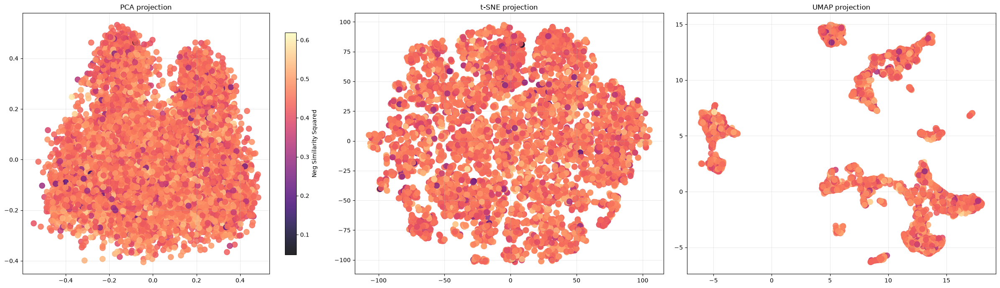

In [ ]:
# images plotted in embedding space projected into 2d
# colored by similarity to respective embedded caption
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from typing import cast
from matplotlib.colors import Normalize
import numpy as np
samples = len(ds_roco)

images = roco_image_embeddings[:samples].cpu().numpy()
texts = roco_caption_embeddings[:samples].cpu().numpy()
similarities = np.sum(images * texts, axis=1)

pca_embeddings = PCA(n_components=2).fit_transform(images)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(images) - 1),
    init="pca",
    random_state=42,
).fit_transform(images)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(images)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    scatter = ax.scatter(
        projected[:, 0],
        projected[:, 1],
        c=similarities,
        cmap="magma",
        norm=Normalize(vmin=similarities.min(), vmax=similarities.max()),
        s=90,
        alpha=0.85,
    )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

fig.colorbar(
    scatter,
    ax=axes[0],
    label="Similarity",
    shrink=0.85,
)

plt.tight_layout()
plt.show()

In [ ]:
# TODO: pick out one bad performing example, show image and caption, and maybe some neighbor pairs in projection space

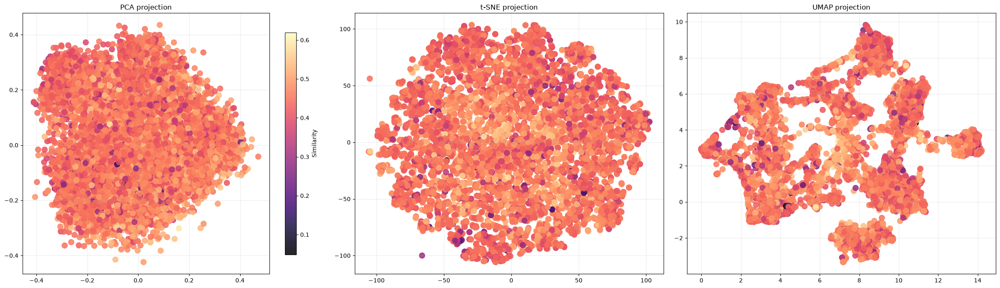

In [ ]:
# captions plotted in embedding space projected into 2d
# colored by similarity to respective embedded image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from matplotlib import pyplot as plt
from typing import cast
from matplotlib.colors import Normalize
import numpy as np
samples = len(ds_roco)

images = roco_image_embeddings[:samples].cpu().numpy()
texts = roco_caption_embeddings[:samples].cpu().numpy()
similarities = np.sum(images * texts, axis=1)

pca_embeddings = PCA(n_components=2).fit_transform(texts)
tsne_embeddings = TSNE(
    n_components=2,
    perplexity=min(5, len(texts) - 1),
    init="pca",
    random_state=42,
).fit_transform(texts)
umap_embeddings = UMAP(
    n_components=2
).fit_transform(texts)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, projected, title in zip(
    axes,
    [pca_embeddings, tsne_embeddings, umap_embeddings],
    ["PCA", "t-SNE", "UMAP"],
):
    scatter = ax.scatter(
        projected[:, 0],
        projected[:, 1],
        c=similarities,
        cmap="magma",
        norm=Normalize(vmin=similarities.min(), vmax=similarities.max()),
        s=90,
        alpha=0.85,
    )
    ax.set_title(f"{title} projection")
    ax.grid(alpha=0.25)

fig.colorbar(
    scatter,
    ax=axes[0],
    label="Similarity",
    shrink=0.85,
)

plt.tight_layout()
plt.show()

# TODO: filter only low similarities

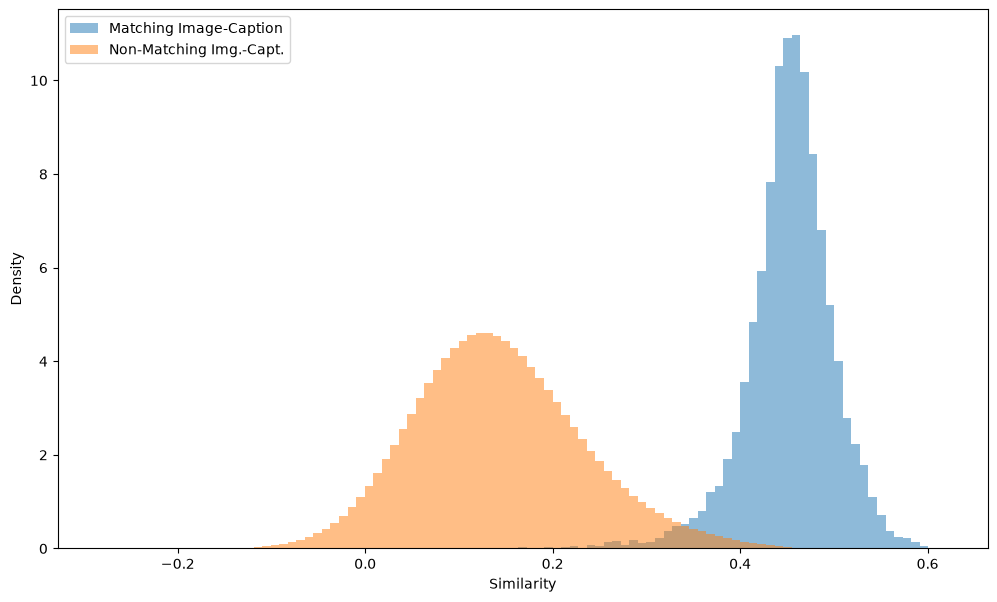

In [ ]:
# density histogram of similarity values between matching image-caption pairs and non-matching pairs
from matplotlib import pyplot as plt
import numpy as np
samples = len(ds_roco)
nbuckets = 100

images = roco_image_embeddings[:samples]
texts = roco_caption_embeddings[:samples]
similarities = (images @ texts.t()).cpu().numpy()

self_similarities = np.diagonal(similarities)
non_self_similarities = similarities[~np.eye(samples, dtype=bool)]

min_similarity = similarities.min()
max_similarity = similarities.max()
buckets = np.linspace(min_similarity, max_similarity, nbuckets)

fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(self_similarities, bins=buckets, alpha=0.5, label='matching image-caption pairs', density=True)
ax.hist(non_self_similarities, bins=buckets, alpha=0.5, label='non-matching img.-capt. pairs', density=True)
ax.set_xlabel('Similarity')
ax.set_ylabel('Density')
ax.legend()
plt.show()

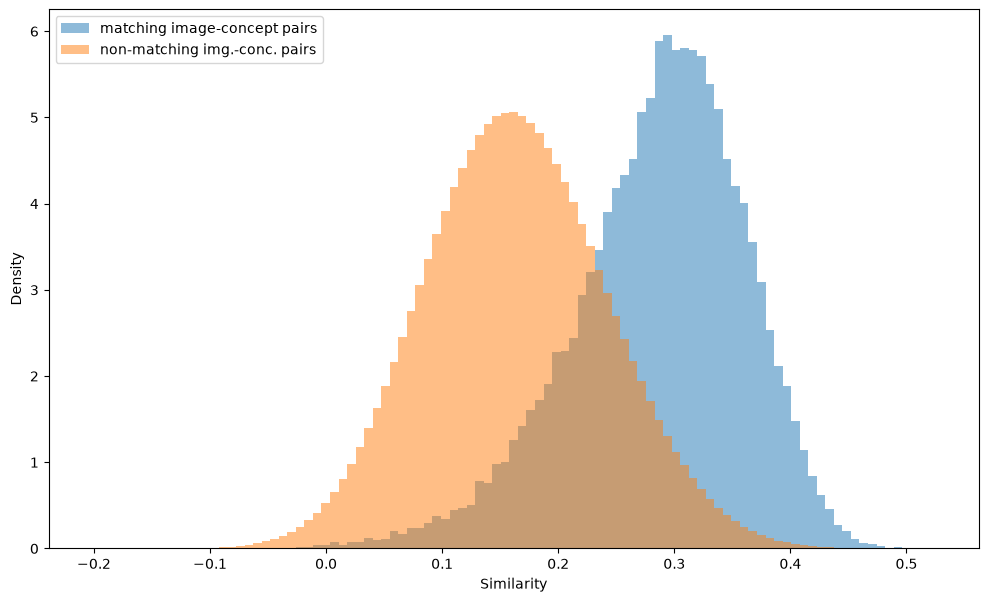

In [ ]:
# density histogram of similarity values between matching image-caption pairs and non-matching pairs
from matplotlib import pyplot as plt
import numpy as np
samples = len(ds_roco)
nbuckets = 100

images = roco_image_embeddings[:samples]
texts = roco_cui_embeddings
similarities = (images @ texts.t()).cpu().numpy()

#concepts: list[list[int]] = ds_roco[:samples]['concepts_manual']
concepts: list[list[int]] = ds_roco[:samples]['concepts']
mask = np.zeros_like(similarities, dtype=bool)
for i, cl in enumerate(concepts):
    for c in cl:
        mask[i, c] = True

self_similarities = similarities[mask]
non_self_similarities = similarities[~mask]

min_similarity = similarities.min()
max_similarity = similarities.max()
buckets = np.linspace(min_similarity, max_similarity, nbuckets)

fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(self_similarities, bins=buckets, alpha=0.5, label='matching image-concept pairs', density=True)
ax.hist(non_self_similarities, bins=buckets, alpha=0.5, label='non-matching img.-conc. pairs', density=True)
ax.set_xlabel('Similarity')
ax.set_ylabel('Density')
ax.legend()
plt.show()

In [ ]:
# TODO: which are the worst performing concepts in the above graph? scatter plot of concepts (x average self-similarity, y average non-self-similarity)

In [ ]:
# TODO: upload my own notebook
# TODO: send all final versions to Thomas

# TODO: test all cells if work correctly from empty directory
# TODO: test on my own xray images

In [ ]:
# TODO: look at internal embedding of the visual transformer (e.g. attention maps) to see if it focuses on relevant areas of the image for certain concepts
#   mode.visual.trunk
# TODO: for samples with at >0 concepts, use secondary language model (or biomedclip itself if you can figure out how) to get what info the caption adds on top of the concepts, i.e. caption-concepts (roco)
#   then check if this more fine-grained context makes difference in accuracy
# TODO: or simpler but less detailed way to do this: check image-retrieval with captions vs concepts vs captions+concepts (does it perform better with more detailed captions)
#   and classification of captions vs concepts vs captions+concepts from image (roco)
# TODO: filter by gender whenever given in caption (male/female, masculine/feminine; only whole words!!! e.g. male is substring of female)
#   -> first enough samples and how biased towards certain gender? (in itself interesting)
#   -> how well can BiomedCLIP distinguish gender from image?